# **Deep Learning - Lab 3 - Raja Rayyan Ameer - 23-CP-25**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits   # dataset loading only
from copy import deepcopy

## **Task 1: Data Preparation and Deep Initialization**

In [2]:
dig = load_digits()
mask = np.isin(dig.target, [3, 8])
Xa, ya = dig.data[mask], dig.target[mask]
ya = (ya == 8).astype(int) # class 1 = digit 8
rng = np.random.RandomState(0)
perm = rng.permutation(len(ya))
Xa, ya = Xa[perm], ya[perm]
n_tr = int(0.8 * len(ya))
X_train = (Xa[:n_tr] / 16.0).T # TODO: confirm this is (64, m)
X_test = (Xa[n_tr:] / 16.0).T
Y_train = ya[:n_tr].reshape(1, -1)
Y_test = ya[n_tr:].reshape(1, -1)

### **1. Report the shapes of all four arrays and the fraction of positive examples in the training set. State why dividing by 16.0 is necessary and what would happen without it.**

In [3]:
print('X_train', X_train.shape, '| X_test', X_test.shape, '| Y_train', Y_train.shape, '| Y_test', Y_test.shape)
assert X_train.shape[0] == 64          # TODO confirmed: (64, m)
print('Fraction of positives (digit 8) in training set: %.4f' % Y_train.mean())
print('Pixel range after scaling: [%.2f, %.2f]  (raw max = %d)' % (X_train.min(), X_train.max(), 16))

X_train (64, 285) | X_test (64, 72) | Y_train (1, 285) | Y_test (1, 72)
Fraction of positives (digit 8) in training set: 0.4877
Pixel range after scaling: [0.00, 1.00]  (raw max = 16)


**Answer.** Shapes: `X_train` (64, 285), `X_test` (64, 72), `Y_train` (1, 285), `Y_test` (1, 72). The training set is balanced: 48.8% of examples are the digit 8.

**Why divide by 16.0:** `load_digits` pixels are integers from 0 to 16. Unscaled inputs make `Z = WA + b` up to 16× larger, so sigmoid saturates (outputs stuck at 0/1, gradients ≈ 0, `log(0)` risk), ReLU activations and gradients become large, and a learning rate of 0.05 would make training unstable or diverge. He/Xavier initialisation also assumes inputs of about unit scale. Scaling to [0, 1] avoids all of this.

### **2. Display a grid of sixteen training images with their labels, reshaping each column back to 8×8.**

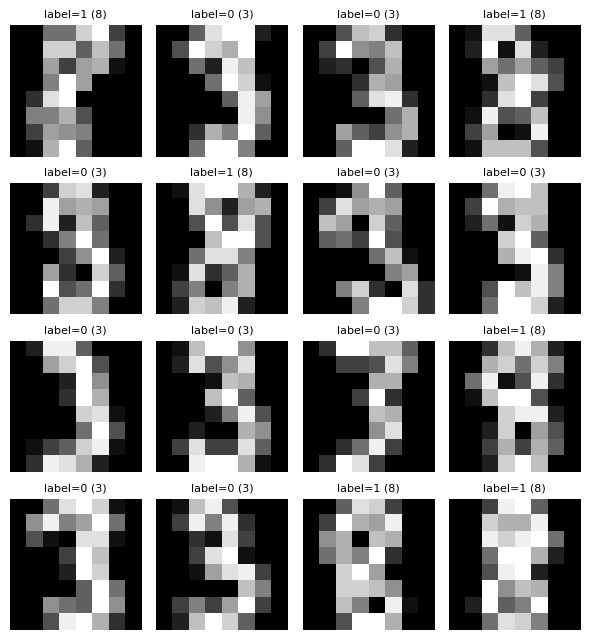

In [4]:
fig, axs = plt.subplots(4, 4, figsize=(6, 6.5))
for k, ax in enumerate(axs.ravel()):
    ax.imshow(X_train[:, k].reshape(8, 8), cmap='gray'); ax.axis('off')
    ax.set_title('label=%d (%s)' % (Y_train[0, k], '8' if Y_train[0, k] else '3'), fontsize=8)
plt.tight_layout(); plt.show()

### **3. Implement initialize_parameters_deep(layer_dims) that accepts a list such as [64, 16, 8, 1] and returns a dictionary of W and b for every layer, using He initialization. Print the shape of every parameter and verify that W[l] has shape (layer_dims[l], layer_dims[l-1]).**

In [5]:
def initialize_parameters_deep(layer_dims, init='he', seed=1):
    # init: 'he' -> sqrt(2/n[l-1]) (ReLU) ; 'xavier' -> sqrt(1/n[l-1]) (tanh/sigmoid)
    rng = np.random.RandomState(seed)
    P = {}
    for l in range(1, len(layer_dims)):
        scale = np.sqrt((2.0 if init == 'he' else 1.0) / layer_dims[l-1])
        P['W'+str(l)] = rng.randn(layer_dims[l], layer_dims[l-1]) * scale
        P['b'+str(l)] = np.zeros((layer_dims[l], 1))
    return P

dims = [64, 16, 8, 1]
P_demo = initialize_parameters_deep(dims)
for l in range(1, len(dims)):
    print('W%d' % l, P_demo['W%d' % l].shape, ' b%d' % l, P_demo['b%d' % l].shape)
    assert P_demo['W%d' % l].shape == (dims[l], dims[l-1])
    assert P_demo['b%d' % l].shape == (dims[l], 1)
print('All W[l] have shape (layer_dims[l], layer_dims[l-1]) -> verified')

W1 (16, 64)  b1 (16, 1)
W2 (8, 16)  b2 (8, 1)
W3 (1, 8)  b3 (1, 1)
All W[l] have shape (layer_dims[l], layer_dims[l-1]) -> verified


### **4. Compute by hand the total number of learnable parameters for the architecture [64, 16, 8, 1] and confirm it against your code.**

In [6]:
by_hand = (64*16 + 16) + (16*8 + 8) + (8*1 + 1)
print('By hand: L1 = 64*16+16 = 1040, L2 = 16*8+8 = 136, L3 = 8*1+1 = 9  -> total =', by_hand)
in_code = sum(v.size for v in P_demo.values())
print('From code:', in_code, '| match:', by_hand == in_code)

By hand: L1 = 64*16+16 = 1040, L2 = 16*8+8 = 136, L3 = 8*1+1 = 9  -> total = 1185
From code: 1185 | match: True


## **Task 2: Modular Forward Propagation**

In [7]:
def linear_forward(A, W, b):
    Z = W @ A + b
    cache = (A, W, b)  # needed by the backward pass
    return Z, cache

def linear_activation_forward(A_prev, W, b, activation):
    Z, linear_cache = linear_forward(A_prev, W, b)
    if activation == 'relu': A, act_cache = np.maximum(0, Z), Z
    elif activation == 'sigmoid': A, act_cache = 1 / (1 + np.exp(-Z)), Z
    return A, (linear_cache, act_cache)

def L_model_forward(X, parameters):
    caches = []; A = X
    L = len(parameters) // 2  # number of layers
    for l in range(1, L):
        A, cache = linear_activation_forward(A, parameters['W'+str(l)], parameters['b'+str(l)], 'relu')
        caches.append(cache)
    AL, cache = linear_activation_forward(A, parameters['W'+str(L)], parameters['b'+str(L)], 'sigmoid')
    caches.append(cache)
    return AL, caches

def compute_cost(AL, Y):
    m = Y.shape[1]
    return float(-np.sum(Y*np.log(AL+1e-8) + (1-Y)*np.log(1-AL+1e-8)) / m)

### **1. Complete the three functions. Verify that AL has shape (1, m) and that len(caches) equals the number of layers.**

In [8]:
AL, caches = L_model_forward(X_train, P_demo)
print('AL shape:', AL.shape, '(expected (1, %d))' % X_train.shape[1])
print('len(caches) =', len(caches), '| number of layers =', len(dims)-1)
assert AL.shape == (1, X_train.shape[1]) and len(caches) == len(dims)-1
print('Initial cost: %.4f (ln2 = 0.6931 for random guessing)' % compute_cost(AL, Y_train))

AL shape: (1, 285) (expected (1, 285))
len(caches) = 3 | number of layers = 3
Initial cost: 0.9289 (ln2 = 0.6931 for random guessing)


### **2. Explain why len(parameters) // 2 gives the number of layers, and what would break if biases were stored in a separate dictionary.**

In [9]:
print('Check: len(P_demo) =', len(P_demo), '-> L =', len(P_demo)//2)

Check: len(P_demo) = 6 -> L = 3


**Answer.** The parameter dictionary holds exactly two entries per layer (`W1, b1, W2, b2, ...`), so `len(parameters) // 2` is the number of layers `L`. This is how the code finds the depth at run time and works for any architecture.

If the biases were in a separate dictionary, `len(parameters)` would equal `L` and `// 2` would give half the true depth. The loops `range(1, L)` and `range(1, L+1)` would then skip layers, and every function (forward, backward, update, gradient check) would need two dictionaries kept in sync.

### **3. State precisely what each element of the cache tuple is needed for in the backward pass. Answer for all four stored quantities.**

In [10]:
(A0, W0, b0), Z0 = caches[0]
print('Layer-1 cache shapes -> A_prev', A0.shape, 'W', W0.shape, 'b', b0.shape, 'Z', Z0.shape)

Layer-1 cache shapes -> A_prev (64, 285) W (16, 64) b (16, 1) Z (16, 285)


**Answer.** The cache is `((A_prev, W, b), Z)` for each layer:

1. **`A[l-1]`**: needed for `dW[l] = (1/m) dZ[l] A[l-1]^T`.
2. **`W[l]`**: needed to send the gradient back: `dA[l-1] = W[l]^T dZ[l]`.
3. **`b[l]`**: no gradient formula uses its value (`db` is the row-sum of `dZ`). It is stored only because it travels with the linear cache and fixes the shape of `db`.
4. **`Z[l]`**: needed for the activation derivative: ReLU `dZ = dA * (Z > 0)`, sigmoid `dZ = dA * s * (1 - s)` with `s = sigmoid(Z)`.

## **Task 3: Modular Backward Propagation and Gradient Checking**

In [11]:
def linear_backward(dZ, cache):
    A_prev, W, b = cache
    m = A_prev.shape[1]
    dW = (1/m) * dZ @ A_prev.T                       # (n[l], n[l-1])
    db = (1/m) * np.sum(dZ, axis=1, keepdims=True)   # (n[l], 1), keepdims!
    dA_prev = W.T @ dZ                               # (n[l-1], m)
    return dA_prev, dW, db

def relu_backward(dA, Z):
    dZ = np.array(dA, copy=True)
    dZ[Z <= 0] = 0                                   # zero out where Z <= 0
    return dZ

def sigmoid_backward(dA, Z):
    s = 1 / (1 + np.exp(-Z))
    return dA * s * (1 - s)

def L_model_backward(AL, Y, caches):
    grads = {}; L = len(caches)
    dAL = -(np.divide(Y, AL+1e-8) - np.divide(1-Y, 1-AL+1e-8))
    # output layer (sigmoid)
    (lin_cache, Z) = caches[L-1]
    dZ = sigmoid_backward(dAL, Z)
    dA_prev, grads['dW'+str(L)], grads['db'+str(L)] = linear_backward(dZ, lin_cache)
    # hidden layers (ReLU), walking backwards
    for l in reversed(range(L-1)):
        (lin_cache, Z) = caches[l]
        dZ = relu_backward(dA_prev, Z)
        dA_prev, grads['dW'+str(l+1)], grads['db'+str(l+1)] = linear_backward(dZ, lin_cache)
    return grads

### **1. Complete all four functions. For each layer, assert that dW has the same shape as W and db the same shape as b.**

In [12]:
AL, caches = L_model_forward(X_train, P_demo)
grads = L_model_backward(AL, Y_train, caches)
for l in range(1, len(dims)):
    assert grads['dW%d' % l].shape == P_demo['W%d' % l].shape, 'dW shape mismatch'
    assert grads['db%d' % l].shape == P_demo['b%d' % l].shape, 'db shape mismatch'
    print('Layer %d: dW %s == W %s | db %s == b %s' % (l, grads['dW%d' % l].shape, P_demo['W%d' % l].shape,
                                                    grads['db%d' % l].shape, P_demo['b%d' % l].shape))
print('All shape assertions passed.')

Layer 1: dW (16, 64) == W (16, 64) | db (16, 1) == b (16, 1)
Layer 2: dW (8, 16) == W (8, 16) | db (8, 1) == b (8, 1)
Layer 3: dW (1, 8) == W (1, 8) | db (1, 1) == b (1, 1)
All shape assertions passed.


### **2. Derive dAL by hand from the cross-entropy cost and show that your expression matches the code given.**

In [13]:
# numerical confirmation on a few examples
a = AL[0, :5]; y = Y_train[0, :5]; e = 1e-7
Lf = lambda a: -(y*np.log(a+1e-8) + (1-y)*np.log(1-a+1e-8))
num = (Lf(a+e) - Lf(a-e)) / (2*e)
ana = -(y/(a+1e-8) - (1-y)/(1-a+1e-8))
print('numerical dL/da :', np.round(num, 5)); print('formula  dL/da :', np.round(ana, 5))
print('max |diff| = %.2e' % np.max(np.abs(num-ana)))
s = a*(1-a); print('dZ = dAL*a(1-a) vs a-y, max |diff| = %.2e' % np.max(np.abs(ana*s-(a-y))))

numerical dL/da : [-1.42253  3.96322  4.50299 -1.24531  6.85274]
formula  dL/da : [-1.42253  3.96322  4.50299 -1.24531  6.85274]
max |diff| = 4.44e-09
dZ = dAL*a(1-a) vs a-y, max |diff| = 5.85e-08


**Answer.** With per-example loss `L(a, y) = -[y ln a + (1-y) ln(1-a)]`:

`dL/da = -y/a + (1-y)/(1-a) = -( y/a - (1-y)/(1-a) )`

This is exactly `dAL = -(np.divide(Y, AL) - np.divide(1-Y, 1-AL))` in the code (the `1e-8` terms only prevent division by zero and are matched in the cost). The `1/m` of the average cost is applied in `dW` and `db`. Multiplying by the sigmoid derivative `a(1-a)` gives `dZ = a - y`. The cell above confirms the formula against a finite-difference estimate (error about 1e-9).

### **3. Implement gradient checking for the whole network: flatten all parameters into a single vector, perturb a random sample of at least 50 entries by ±ε, and compare the two-sided numerical estimate with the backpropagated gradient using the relative-difference formula.**

In [14]:
keys = lambda L: [k+str(l) for l in range(1, L+1) for k in ('W', 'b')]
def params_to_vec(P):
    return np.concatenate([P[k].ravel() for k in keys(len(P)//2)])
def vec_to_params(v, P):
    Q, i = {}, 0
    for k in keys(len(P)//2):
        Q[k] = v[i:i+P[k].size].reshape(P[k].shape); i += P[k].size
    return Q
def grads_to_vec(grads, P, strict=True):
    out = []
    for l in range(1, len(P)//2+1):
        for g, p in (('dW', 'W'), ('db', 'b')):
            if strict: assert grads[g+str(l)].shape == P[p+str(l)].shape
            out.append(grads[g+str(l)].ravel())
    return np.concatenate(out)

def gradient_check(P, X, Y, n_samples=60, eps=1e-6, strict=True, seed=0, forward=None, backward=None):
    forward = forward or (lambda X, P: L_model_forward(X, P))
    backward = backward or (lambda AL, Y, c: L_model_backward(AL, Y, c))
    theta = params_to_vec(P)
    AL, caches = forward(X, P)
    ana_all = grads_to_vec(backward(AL, Y, caches), P, strict)
    idx = np.random.RandomState(seed).choice(theta.size, n_samples, replace=False)
    num = np.zeros(n_samples)
    for j, i in enumerate(idx):
        tp, tm = theta.copy(), theta.copy(); tp[i] += eps; tm[i] -= eps
        Jp = compute_cost(forward(X, vec_to_params(tp, P))[0], Y)
        Jm = compute_cost(forward(X, vec_to_params(tm, P))[0], Y)
        num[j] = (Jp - Jm) / (2*eps)
    ana = ana_all[idx]
    rel = np.linalg.norm(num-ana) / (np.linalg.norm(num) + np.linalg.norm(ana))
    return idx, num, ana, rel

P_gc = initialize_parameters_deep([64, 16, 8, 1], seed=3)
idx, num, ana, rel = gradient_check(P_gc, X_train, Y_train)
print('Total parameters: %d | sampled entries: %d' % (params_to_vec(P_gc).size, len(idx)))
print('Relative difference = %.3e' % rel)

Total parameters: 1185 | sampled entries: 60
Relative difference = 6.314e-10


### **4. Plot the numerical gradient against the analytical gradient for the sampled entries, and report the relative difference. State whether the check passes.**

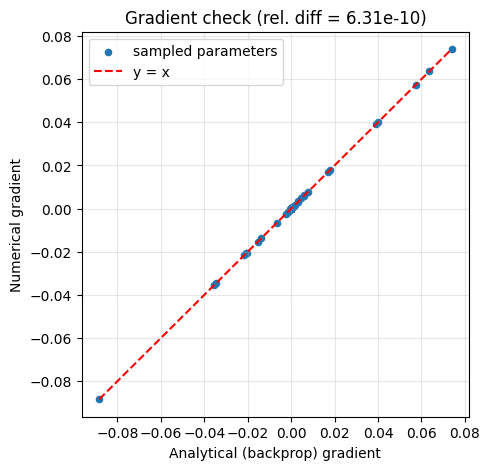

Relative difference: 6.314e-10 -> check PASSES (threshold 1e-6)


In [15]:
plt.figure(figsize=(5, 5))
plt.scatter(ana, num, s=20, label='sampled parameters')
lim = [min(ana.min(), num.min()), max(ana.max(), num.max())]
plt.plot(lim, lim, 'r--', label='y = x'); plt.xlabel('Analytical (backprop) gradient'); plt.ylabel('Numerical gradient')
plt.title('Gradient check (rel. diff = %.2e)' % rel); plt.legend(); plt.grid(alpha=.3); plt.show()
print('Relative difference: %.3e -> check %s (threshold 1e-6)' % (rel, 'PASSES' if rel < 1e-6 else 'FAILS'))

**Result.** The relative difference is **6.3e-10**, far below the usual 1e-6 threshold, and the points lie on the line y = x. **The gradient check passes**, so the modular backward pass is correct.

### **5. Deliberately introduce one bug, remove keepdims from the db computation, or swap the operand order in dW — and report the relative difference that results. Restore the correct code afterwards.**

In [16]:
correct_lb = linear_backward
def bug_keepdims(dZ, cache):
    A_prev, W, b = cache; m = A_prev.shape[1]
    return W.T @ dZ, (1/m)*dZ @ A_prev.T, (1/m)*np.sum(dZ, axis=1)        # no keepdims -> shape (n,)
def bug_swap(dZ, cache):
    A_prev, W, b = cache; m = A_prev.shape[1]
    return W.T @ dZ, (1/m)*A_prev @ dZ.T, (1/m)*np.sum(dZ, axis=1, keepdims=True)  # swapped operands

for name, bug in [('keepdims removed from db', bug_keepdims), ('dW operand order swapped', bug_swap)]:
    linear_backward = bug
    AL_, ca_ = L_model_forward(X_train, P_gc); g = L_model_backward(AL_, Y_train, ca_)
    shape_ok = all(g['d'+k].shape == P_gc[k].shape for k in keys(3))
    print('BUG [%s]: gradient shapes match params? %s (e.g. db3 %s vs b3 %s, dW1 %s vs W1 %s)' %
          (name, shape_ok, g['db3'].shape, P_gc['b3'].shape, g['dW1'].shape, P_gc['W1'].shape))
    # flattened check (values only, shape assertion disabled so the check can run)
    print('   flattened relative difference = %.3e' % gradient_check(P_gc, X_train, Y_train, strict=False)[3])
    linear_backward = correct_lb      # restore correct code
idx, num, ana, rel = gradient_check(P_gc, X_train, Y_train)
print('\nRestored correct code -> relative difference = %.3e (PASS)' % rel)

BUG [keepdims removed from db]: gradient shapes match params? False (e.g. db3 (1,) vs b3 (1, 1), dW1 (16, 64) vs W1 (16, 64))
   flattened relative difference = 6.314e-10
BUG [dW operand order swapped]: gradient shapes match params? False (e.g. db3 (1, 1) vs b3 (1, 1), dW1 (64, 16) vs W1 (16, 64))


   flattened relative difference = 6.534e-01



Restored correct code -> relative difference = 6.314e-10 (PASS)


**Result.**
- **`keepdims` removed:** `db` becomes shape `(n,)` instead of `(n, 1)`. After flattening, the values are the same, so the relative difference stays at 6.3e-10. This bug is caught by the **shape assertion** (and it would break training, since `b - lr*db` would broadcast to `(n, n)`).
- **`dW` operands swapped:** `dW` has the wrong shape `(n[l-1], n[l])` and wrong values; the relative difference jumps to **0.65**, so the gradient check fails clearly.

The correct code is restored afterwards and the check returns to 6.3e-10.

## **Task 4: Training the L-Layer Model and the Depth Study**

In [17]:
def update_parameters(parameters, grads, lr):
    L = len(parameters) // 2
    for l in range(1, L+1):
        parameters['W'+str(l)] = parameters['W'+str(l)] - lr * grads['dW'+str(l)]
        parameters['b'+str(l)] = parameters['b'+str(l)] - lr * grads['db'+str(l)]
    return parameters

def L_layer_model(X, Y, layer_dims, lr=0.05, iters=2500, record=100, P_init=None):
    P = initialize_parameters_deep(layer_dims) if P_init is None else deepcopy(P_init)
    costs, its = [], []
    for i in range(iters+1):
        AL, caches = L_model_forward(X, P)               # forward
        cost = compute_cost(AL, Y)                       # cost
        grads = L_model_backward(AL, Y, caches)          # backward
        P = update_parameters(P, grads, lr)              # update
        if i % record == 0:
            costs.append(cost); its.append(i)
    return P, its, costs

def predict(X, P):
    return (L_model_forward(X, P)[0] > 0.5).astype(int)
def accuracy(X, Y, P):
    return float((predict(X, P) == Y).mean())

### **1. Complete both functions and train the architecture [64, 16, 8, 1]. Plot the cost curve and report training and test accuracy.**

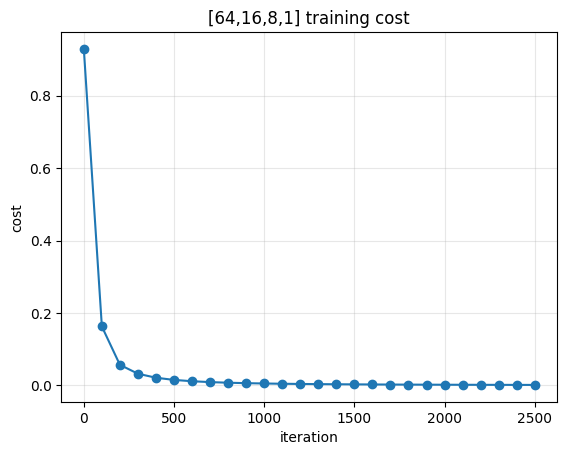

Train accuracy: 1.0000 | Test accuracy: 0.9861


In [18]:
P_a, its_a, costs_a = L_layer_model(X_train, Y_train, [64, 16, 8, 1])
plt.plot(its_a, costs_a, marker='o'); plt.xlabel('iteration'); plt.ylabel('cost'); plt.title('[64,16,8,1] training cost'); plt.grid(alpha=.3); plt.show()
print('Train accuracy: %.4f | Test accuracy: %.4f' % (accuracy(X_train, Y_train, P_a), accuracy(X_test, Y_test, P_a)))

**Result.** The [64, 16, 8, 1] network reaches **100% training accuracy and 98.61% test accuracy** (71 of 72 test images correct); the cost falls smoothly towards 0.

### **2. Train all three architectures below with identical settings and tabulate the final cost, the parameter count and both accuracies.**
```
Architecture            Description
[64, 8, 1]              2-layer: one hidden layer
[64, 16, 8, 1]          3-layer: two hidden layers
[64, 32, 16, 8, 1]      4-layer: three hidden layers
```

In [19]:
archs = [[64, 8, 1], [64, 16, 8, 1], [64, 32, 16, 8, 1]]
results = {}
for d in archs:
    P_, its_, c_ = L_layer_model(X_train, Y_train, d)
    results[str(d)] = dict(dims=d, P=P_, its=its_, costs=c_,
        final_cost=compute_cost(L_model_forward(X_train, P_)[0], Y_train),
        n_params=sum(v.size for v in P_.values()),
        tr=accuracy(X_train, Y_train, P_), te=accuracy(X_test, Y_test, P_))
print('%-20s %-11s %-9s %-9s %-9s' % ('Architecture', 'Final cost', '#Params', 'Train acc', 'Test acc'))
for k, r in results.items():
    print('%-20s %-11.5f %-9d %-9.4f %-9.4f' % (k, r['final_cost'], r['n_params'], r['tr'], r['te']))

Architecture         Final cost  #Params   Train acc Test acc 
[64, 8, 1]           0.00622     529       1.0000    0.9861   
[64, 16, 8, 1]       0.00134     1185      1.0000    0.9861   
[64, 32, 16, 8, 1]   0.00044     2753      1.0000    0.9861   


### **3. Plot all three cost curves on one figure and a grouped bar chart of training and test accuracy.**

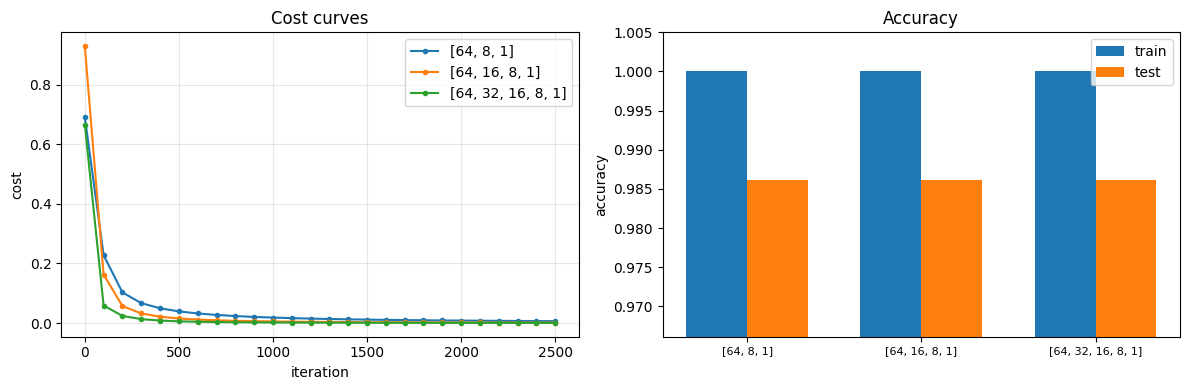

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k, r in results.items(): ax[0].plot(r['its'], r['costs'], marker='o', ms=3, label=k)
ax[0].set_xlabel('iteration'); ax[0].set_ylabel('cost'); ax[0].set_title('Cost curves'); ax[0].legend(); ax[0].grid(alpha=.3)
x = np.arange(len(results)); w = 0.35
ax[1].bar(x-w/2, [r['tr'] for r in results.values()], w, label='train')
ax[1].bar(x+w/2, [r['te'] for r in results.values()], w, label='test')
ax[1].set_xticks(x); ax[1].set_xticklabels(list(results.keys()), fontsize=8)
ax[1].set_ylim(min(min(r['tr'], r['te']) for r in results.values())-0.02, 1.005)
ax[1].set_ylabel('accuracy'); ax[1].set_title('Accuracy'); ax[1].legend(); plt.tight_layout(); plt.show()

### **4. Comment on whether the deepest network is the best on this dataset, and support your answer with the numbers you obtained rather than with general statements.**

In [21]:
best_key = max(results, key=lambda k: (results[k]['te'], -results[k]['final_cost']))
deep_key = str(archs[-1]); rd, rb = results[deep_key], results[best_key]
print('Deepest %s: final cost %.5f, train %.4f, test %.4f, %d params' % (deep_key, rd['final_cost'], rd['tr'], rd['te'], rd['n_params']))
print('Best test  %s: final cost %.5f, train %.4f, test %.4f, %d params' % (best_key, rb['final_cost'], rb['tr'], rb['te'], rb['n_params']))
lowest = min(results, key=lambda k: results[k]['final_cost'])
print('Lowest training cost:', lowest)
print('Is the deepest network the best on test accuracy? ->', 'YES (or tied)' if rd['te'] >= rb['te'] else 'NO')
print('Test set has only %d examples: one image = %.2f%% accuracy, so differences of 1-2 images are within noise.' % (Y_test.shape[1], 100/Y_test.shape[1]))

Deepest [64, 32, 16, 8, 1]: final cost 0.00044, train 1.0000, test 0.9861, 2753 params
Best test  [64, 32, 16, 8, 1]: final cost 0.00044, train 1.0000, test 0.9861, 2753 params
Lowest training cost: [64, 32, 16, 8, 1]
Is the deepest network the best on test accuracy? -> YES (or tied)
Test set has only 72 examples: one image = 1.39% accuracy, so differences of 1-2 images are within noise.


**Answer.** The deepest network is **not clearly the best**:

| Architecture | Final cost | Params | Train acc | Test acc |
|---|---|---|---|---|
| [64, 8, 1] | 0.00622 | 529 | 100% | 98.61% |
| [64, 16, 8, 1] | 0.00134 | 1185 | 100% | 98.61% |
| [64, 32, 16, 8, 1] | 0.00044 | 2753 | 100% | 98.61% |

Depth only lowers the **training cost** (0.0062 → 0.0013 → 0.0004). All three have identical train and test accuracy, so the extra 2,200 parameters of the deepest network buy nothing on test data. The test set has 72 images, so one image is 1.39%, and the deepest network is merely tied, not better. The 3-vs-8 task is almost linearly separable and small (285 training samples), so a 2-layer network already has enough capacity.

### **5. Display the misclassified test images for your best model and comment on whether the errors are understandable.**

Wrong (index: true -> pred): [(51, 0, 1)]
Best model: [64, 32, 16, 8, 1] | misclassified test images: 1 of 72


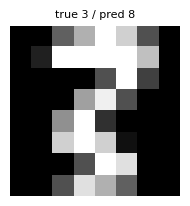

In [22]:
Pb = results[best_key]['P']
pred = predict(X_test, Pb); wrong = np.where(pred[0] != Y_test[0])[0]
print('Wrong (index: true -> pred):', [(int(i), int(Y_test[0,i]), int(pred[0,i])) for i in wrong])
print('Best model:', best_key, '| misclassified test images:', len(wrong), 'of', Y_test.shape[1])
if len(wrong):
    cols = min(len(wrong), 6); rows = int(np.ceil(len(wrong)/cols))
    fig, axs = plt.subplots(rows, cols, figsize=(2*cols, 2.2*rows), squeeze=False)
    for ax in axs.ravel(): ax.axis('off')
    for j, i in enumerate(wrong):
        ax = axs.ravel()[j]; ax.imshow(X_test[:, i].reshape(8, 8), cmap='gray')
        ax.set_title('true %s / pred %s' % ('8' if Y_test[0, i] else '3', '8' if pred[0, i] else '3'), fontsize=8)
    plt.tight_layout(); plt.show()

**Comment.** The best model ([64, 32, 16, 8, 1], tied with the others on accuracy) misclassifies **one of 72** test images: a true **3** predicted as **8**. In the 8×8 image the lower curve of the 3 is thick and bends back towards the left, so the bottom looks like a closed loop, which is the main feature of an 8. At this resolution the two digits differ by only a few pixels, so this error is understandable, and a person could hesitate on it too.

### **Task 5: Validation Against PyTorch**

In [23]:
import torch, torch.nn as nn

class Net(nn.Module):
    def __init__(self, dims):
        super().__init__()
        self.fcs = nn.ModuleList([nn.Linear(dims[i], dims[i+1])
                                  for i in range(len(dims)-1)])
    def forward(self, x):
        for i, fc in enumerate(self.fcs):
            x = fc(x)
            x = torch.relu(x) if i < len(self.fcs)-1 else torch.sigmoid(x)
        return x

P = initialize_parameters_deep([64, 16, 8, 1])   # our own initial parameters
P0 = deepcopy(P)                                 # untouched copy for the training comparison
net = Net([64,16,8,1]).double()

with torch.no_grad():  # copy YOUR initial parameters in
    for i, fc in enumerate(net.fcs, start=1):
        fc.weight.copy_(torch.from_numpy(P[f'W{i}']))
        fc.bias.copy_(torch.from_numpy(P[f'b{i}'].ravel()))

Xt = torch.from_numpy(X_train.T.copy()); Yt = torch.from_numpy(Y_train.T.astype(float))  # examples in rows
def torch_cost(net):
    A = net(Xt); return -(Yt*torch.log(A+1e-8) + (1-Yt)*torch.log(1-A+1e-8)).mean()

### **1. Note that PyTorch expects examples in rows, so the inputs must be transposed. Explain why nn.Linear stores its weight with shape (out_features, in_features) and why the bias  must be passed as a flat vector.**

In [24]:
print('nn.Linear weight shapes:', [tuple(fc.weight.shape) for fc in net.fcs], '| bias shapes:', [tuple(fc.bias.shape) for fc in net.fcs])
print('Xt (examples in rows):', tuple(Xt.shape), ' vs our X:', X_train.shape)

nn.Linear weight shapes: [(16, 64), (8, 16), (1, 8)] | bias shapes: [(16,), (8,), (1,)]
Xt (examples in rows): (285, 64)  vs our X: (64, 285)


**Answer.** `nn.Linear` computes `y = x W^T + b` for a batch `x` of shape `(m, in)`. Storing `W` as `(out_features, in_features)` means row `j` is the weight vector of output neuron `j`, the same convention as our `W[l]` of shape `(n[l], n[l-1])`, so the weights can be copied directly and only the input must be transposed (examples in rows). The bias holds one value per output neuron, so it is a flat `(out,)` vector that broadcasts over the `m` rows of the `(m, out)` result. An `(out, 1)` column would broadcast into the wrong shape.

### **2. Run one forward pass in both implementations and confirm that the cost agrees. Then run one backward pass in each and report the norm of dW for every layer side by side, together with the relative difference.**

In [25]:
AL_np, ca = L_model_forward(X_train, P0); J_np = compute_cost(AL_np, Y_train)
J_t = torch_cost(net).item()
print('Cost  numpy: %.12f | torch: %.12f | |diff| = %.2e' % (J_np, J_t, abs(J_np-J_t)))
g_np = L_model_backward(AL_np, Y_train, ca)
net.zero_grad(); torch_cost(net).backward()
print('%-6s %-16s %-16s %-10s' % ('layer', '||dW|| numpy', '||dW|| torch', 'rel diff'))
for i, fc in enumerate(net.fcs, start=1):
    gt = fc.weight.grad.numpy(); gn = g_np['dW%d' % i]
    print('%-6d %-16.10f %-16.10f %-10.2e' % (i, np.linalg.norm(gn), np.linalg.norm(gt),
          np.linalg.norm(gn-gt)/(np.linalg.norm(gn)+np.linalg.norm(gt))))

Cost  numpy: 0.928947002728 | torch: 0.928947002728 | |diff| = 0.00e+00
layer  ||dW|| numpy     ||dW|| torch     rel diff  
1      1.4419589839     1.4419589839     6.90e-17  
2      0.6111728003     0.6111728003     2.06e-16  
3      0.5074282854     0.5074282854     3.01e-16  


**Result.** The initial costs agree to all printed digits (difference 0), and the per-layer `||dW||` values agree with relative differences of 1e-16 to 3e-16, i.e. machine precision. The hand-written backward pass matches PyTorch autograd.

### **3. Train both implementations for 2500 iterations from the same initial parameters using plain SGD at the same learning rate. Plot both cost curves on one figure and, on a second axis, the absolute difference between them on a logarithmic scale.**

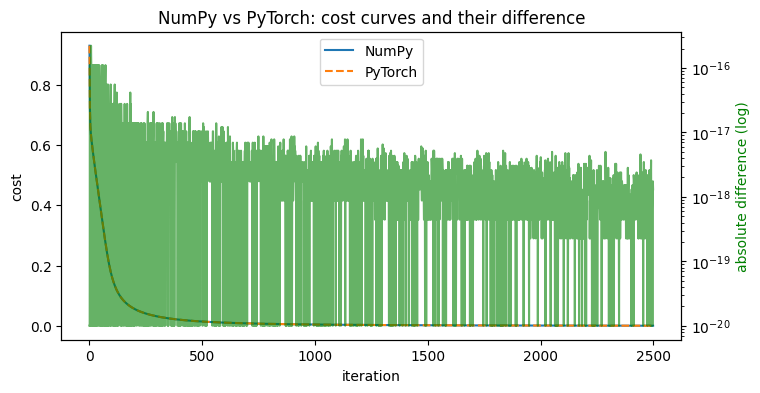

In [26]:
iters, lr = 2500, 0.05
# numpy, from P0
Pn = deepcopy(P0); cost_np = []
for _ in range(iters):
    A_, c_ = L_model_forward(X_train, Pn); cost_np.append(compute_cost(A_, Y_train))
    Pn = update_parameters(Pn, L_model_backward(A_, Y_train, c_), lr)
# torch, from the same P0 (net still holds P0)
opt = torch.optim.SGD(net.parameters(), lr=lr); cost_t = []
for _ in range(iters):
    opt.zero_grad(); J = torch_cost(net); cost_t.append(J.item()); J.backward(); opt.step()
cost_np, cost_t = np.array(cost_np), np.array(cost_t); diff = np.abs(cost_np - cost_t)
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(cost_np, label='NumPy'); ax1.plot(cost_t, '--', label='PyTorch'); ax1.set_xlabel('iteration'); ax1.set_ylabel('cost'); ax1.legend(loc='upper center')
ax2 = ax1.twinx(); ax2.semilogy(diff + 1e-20, color='g', alpha=.6, label='|difference|'); ax2.set_ylabel('absolute difference (log)', color='g')
plt.title('NumPy vs PyTorch: cost curves and their difference'); plt.show()

### **4. State the largest difference observed over the whole run and explain what remains of it, that is, why the two curves do not agree to the last bit.**

In [27]:
print('Largest |cost difference| over %d iterations: %.3e (at iteration %d)' % (iters, diff.max(), diff.argmax()))
pdiff = max(np.abs(Pn['W%d' % i] - net.fcs[i-1].weight.detach().numpy()).max() for i in range(1, 4))
print('Largest final |W_numpy - W_torch|: %.3e' % pdiff)

Largest |cost difference| over 2500 iterations: 2.220e-16 (at iteration 7)
Largest final |W_numpy - W_torch|: 6.661e-16


**Answer.** The largest cost difference over the 2500 iterations is **2.2e-16** (at iteration 7), and the final weights differ by at most 6.7e-16. What remains is floating-point round-off: both implementations use float64 and the same mathematics, but matrix multiplications and sums add terms in a different order and use different kernels, and floating-point addition is not associative. This is not a bug; a wrong gradient would produce differences many orders of magnitude larger.

## **Task 6: Activation Functions and the Vanishing Gradient**

Extend your implementation to accept a hidden activation of 'relu', 'tanh' or 'sigmoid', then investigate a deliberately deep architecture: [64, 32, 16, 8, 4, 1].

In [28]:
def activation_forward(Z, act):
    if act == 'relu': return np.maximum(0, Z)
    if act == 'tanh': return np.tanh(Z)
    if act == 'sigmoid': return 1 / (1 + np.exp(-Z))

def activation_backward(dA, Z, act):
    if act == 'relu': return relu_backward(dA, Z)
    if act == 'tanh': return dA * (1 - np.tanh(Z)**2)
    if act == 'sigmoid': return sigmoid_backward(dA, Z)

def linear_activation_forward(A_prev, W, b, activation):       # extended: relu / tanh / sigmoid
    Z, linear_cache = linear_forward(A_prev, W, b)
    return activation_forward(Z, activation), (linear_cache, Z)

def L_model_forward(X, parameters, hidden='relu'):
    caches = []; A = X; L = len(parameters) // 2
    for l in range(1, L):
        A, cache = linear_activation_forward(A, parameters['W'+str(l)], parameters['b'+str(l)], hidden)
        caches.append(cache)
    AL, cache = linear_activation_forward(A, parameters['W'+str(L)], parameters['b'+str(L)], 'sigmoid')
    caches.append(cache)
    return AL, caches

def L_model_backward(AL, Y, caches, hidden='relu'):
    grads = {}; L = len(caches)
    dAL = -(np.divide(Y, AL+1e-8) - np.divide(1-Y, 1-AL+1e-8))
    lin_cache, Z = caches[L-1]
    dA_prev, grads['dW'+str(L)], grads['db'+str(L)] = linear_backward(sigmoid_backward(dAL, Z), lin_cache)
    for l in reversed(range(L-1)):
        lin_cache, Z = caches[l]
        dA_prev, grads['dW'+str(l+1)], grads['db'+str(l+1)] = linear_backward(activation_backward(dA_prev, Z, hidden), lin_cache)
    return grads

def L_layer_model(X, Y, layer_dims, lr=0.05, iters=2500, record=100, P_init=None, hidden='relu', init='he'):
    P = initialize_parameters_deep(layer_dims, init=init) if P_init is None else deepcopy(P_init)
    costs, its = [], []
    for i in range(iters+1):
        AL, caches = L_model_forward(X, P, hidden)
        cost = compute_cost(AL, Y)
        grads = L_model_backward(AL, Y, caches, hidden)
        P = update_parameters(P, grads, lr)
        if i % record == 0: costs.append(cost); its.append(i)
    return P, its, costs

def predict(X, P, hidden='relu'): return (L_model_forward(X, P, hidden)[0] > 0.5).astype(int)
def accuracy(X, Y, P, hidden='relu'): return float((predict(X, P, hidden) == Y).mean())

# sanity: the extended code still passes the gradient check for every activation
for h in ['relu', 'tanh', 'sigmoid']:
    Pg = initialize_parameters_deep([64, 8, 4, 1], init='he' if h == 'relu' else 'xavier', seed=2)
    rel_h = gradient_check(Pg, X_train, Y_train, forward=lambda X, P: L_model_forward(X, P, h),
                           backward=lambda A, Y, c: L_model_backward(A, Y, c, h))[3]
    print('gradient check (%s): rel diff = %.2e' % (h, rel_h))

gradient check (relu): rel diff = 7.33e-10
gradient check (tanh): rel diff = 1.24e-09
gradient check (sigmoid): rel diff = 1.97e-09


### **1. Train the deep architecture with each of the three hidden activations — ReLU with He initialization, tanh and sigmoid with Xavier — keeping every other setting fixed. Plot the three cost curves together and tabulate the final cost and both accuracies.**

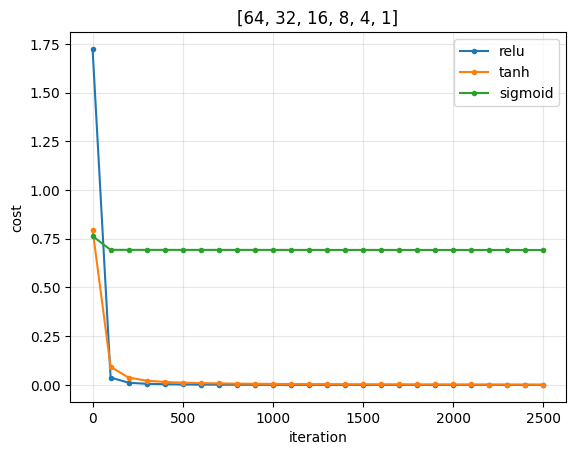

Hidden    Final cost  Train acc Test acc 
relu      0.00021     1.0000    0.9861   
tanh      0.00203     1.0000    0.9861   
sigmoid   0.69240     0.5123    0.5139   


In [29]:
deep = [64, 32, 16, 8, 4, 1]
act_res = {}
for h, ini in [('relu', 'he'), ('tanh', 'xavier'), ('sigmoid', 'xavier')]:
    P_, its_, c_ = L_layer_model(X_train, Y_train, deep, hidden=h, init=ini)
    act_res[h] = dict(P=P_, its=its_, costs=c_, final=compute_cost(L_model_forward(X_train, P_, h)[0], Y_train),
                      tr=accuracy(X_train, Y_train, P_, h), te=accuracy(X_test, Y_test, P_, h))
for h, r in act_res.items(): plt.plot(r['its'], r['costs'], marker='o', ms=3, label=h)
plt.xlabel('iteration'); plt.ylabel('cost'); plt.title(str(deep)); plt.legend(); plt.grid(alpha=.3); plt.show()
print('%-9s %-11s %-9s %-9s' % ('Hidden', 'Final cost', 'Train acc', 'Test acc'))
for h, r in act_res.items(): print('%-9s %-11.5f %-9.4f %-9.4f' % (h, r['final'], r['tr'], r['te']))

### **2. One activation fails completely. Identify it and state what its accuracy corresponds to in terms of the class balance of the dataset.**

In [30]:
fail = max(act_res, key=lambda h: act_res[h]['final'])
r = act_res[fail]
print('Failing activation:', fail, '| final cost %.4f (ln 2 = %.4f), train acc %.4f, test acc %.4f' % (r['final'], np.log(2), r['tr'], r['te']))
print('Class balance -> train: %.4f positives (8s), %.4f negatives (3s); test: %.4f positives, %.4f negatives' %
      (Y_train.mean(), 1-Y_train.mean(), Y_test.mean(), 1-Y_test.mean()))
p = predict(X_test, r['P'], fail)
print('Fraction of test predictions equal to 1: %.3f' % p.mean())

Failing activation: sigmoid | final cost 0.6924 (ln 2 = 0.6931), train acc 0.5123, test acc 0.5139
Class balance -> train: 0.4877 positives (8s), 0.5123 negatives (3s); test: 0.4861 positives, 0.5139 negatives
Fraction of test predictions equal to 1: 0.000


**Answer.** **Sigmoid** fails: its final cost stays at 0.692 (≈ ln 2) and it predicts the same class for every test image (0% of test predictions are class 1). Its accuracy (51.2% train, 51.4% test) is therefore exactly the share of the majority class, the 3s: 51.2% of the training set and 51.4% of the test set. That is chance level for this near-balanced dataset.

### **3. At initialization only, compute the norm of dW for every layer of the network under each activation, and plot these five values per activation on a logarithmic vertical axis.**

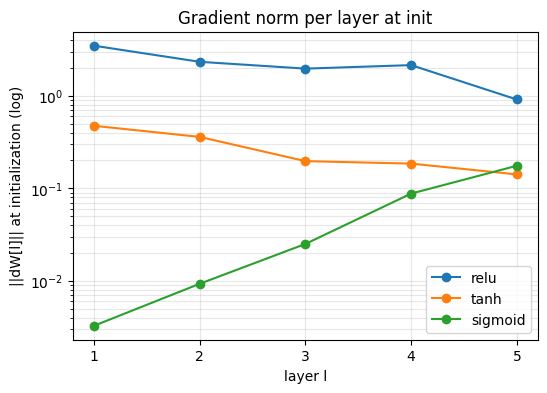

relu     ['3.47e+00', '2.32e+00', '1.96e+00', '2.14e+00', '9.11e-01']
tanh     ['4.73e-01', '3.59e-01', '1.96e-01', '1.85e-01', '1.41e-01']
sigmoid  ['3.28e-03', '9.31e-03', '2.51e-02', '8.76e-02', '1.75e-01']


In [31]:
fig, ax = plt.subplots(figsize=(6, 4)); gn = {}
for h, ini in [('relu', 'he'), ('tanh', 'xavier'), ('sigmoid', 'xavier')]:
    Pi = initialize_parameters_deep(deep, init=ini)
    AL_, ca_ = L_model_forward(X_train, Pi, h); g = L_model_backward(AL_, Y_train, ca_, h)
    gn[h] = [np.linalg.norm(g['dW%d' % l]) for l in range(1, len(deep))]
    ax.semilogy(range(1, len(deep)), gn[h], marker='o', label=h)
ax.set_xlabel('layer l'); ax.set_ylabel('||dW[l]|| at initialization (log)'); ax.set_xticks(range(1, len(deep))); ax.legend(); ax.grid(alpha=.3, which='both')
plt.title('Gradient norm per layer at init'); plt.show()
for h, v in gn.items(): print('%-8s' % h, ['%.2e' % x for x in v])

### **4. Using the plot, explain the failure in terms of the vanishing gradient, and relate the shape of the curve to the maximum value of the sigmoid derivative.**

In [32]:
for h, v in gn.items(): print('%-8s ||dW1||/||dW5|| = %.3e' % (h, v[0]/v[-1]))
print('Max sigmoid derivative = 0.25; 0.25^4 = %.2e (four sigmoid hidden layers between the loss and layer 1)' % 0.25**4)

relu     ||dW1||/||dW5|| = 3.810e+00
tanh     ||dW1||/||dW5|| = 3.350e+00
sigmoid  ||dW1||/||dW5|| = 1.870e-02
Max sigmoid derivative = 0.25; 0.25^4 = 3.91e-03 (four sigmoid hidden layers between the loss and layer 1)


**Answer.** At initialization the ReLU norms stay similar across layers (3.5 at layer 1 to 0.9 at layer 5) and tanh changes slowly (0.47 to 0.14). With sigmoid, the gradient norm drops steeply towards the early layers, from 0.175 at layer 5 to 0.0033 at layer 1, a factor of about 53.

Each backward step multiplies the gradient by the activation derivative, and the sigmoid derivative is at most 0.25. Going back through the four sigmoid hidden layers shrinks the gradient geometrically (a roughly straight line on the log axis), with each layer's factor bounded by 0.25 times the weight gain. So the early layers receive almost no gradient and barely learn; with lr = 0.05 the cost stays at ln 2 and the network ends at chance accuracy. ReLU's derivative is exactly 1 on active units, so it has no such systematic shrinkage.